# Brent–WTI Spread Forecasting

This notebook presents the main workflow of the project, from raw data cleaning to forecasting and portfolio construction.

The objective is to test whether oil market fundamentals improve the prediction of the monthly variation of the Brent–WTI spread.

# 1. Imports

In [26]:
from pathlib import Path
import pandas as pd
from statsmodels.tsa.stattools import adfuller
from scripts.cleaning import clean_eia_prices, clean_jodi_oil
from scripts.plot import plot_spot_prices, plot_spread
from scripts.features import build_monthly_price_features, build_model_dataset
from scripts.tests import check_missing_values, last_complete_date, summarize_model_sample
from scripts.models import (
    get_models,
    forecast_metrics,
    run_overfitting_diagnostics,
)

# 2. Project Paths

Define the project directory structure and the locations of raw and processed datasets.

In [27]:
PROJECT_DIR = Path.cwd()
RAW_EIA_DIR = PROJECT_DIR / "data" / "EIA"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

BRENT_FILE = RAW_EIA_DIR / "spot_brent.csv"
WTI_FILE = RAW_EIA_DIR / "spot_wti.csv"
JODI_DIR = PROJECT_DIR / "data" / "JODI"

JODI_CLEAN_FILE = PROCESSED_DIR / "jodi_oil_clean.csv"
CLEAN_PRICES_FILE = PROCESSED_DIR / "eia_spot_prices_clean.csv"
MONTHLY_PRICE_FEATURES_FILE = PROCESSED_DIR / "monthly_price_features.csv"
MODEL_DATASET_FILE = PROCESSED_DIR / "model_dataset.csv"

# 3. EIA Spot Prices

This section loads and cleans the daily Brent and WTI spot price series from the EIA/FRED data.

The two daily price series are merged on common trading dates and saved as a cleaned dataset.

In [28]:
prices = clean_eia_prices(
    brent_path=BRENT_FILE,
    wti_path=WTI_FILE,
    output_path=CLEAN_PRICES_FILE,
)

prices.head()

,date,Brent,WTI
0,1987-05-20,18.63,19.75
1,1987-05-21,18.45,19.95
2,1987-05-22,18.55,19.68
3,1987-05-26,18.63,19.35
4,1987-05-27,18.60,19.38


## 3.1 Price visualisation

We first plot the Brent and WTI spot prices and the Brent–WTI spread to inspect the main dynamics of the series.

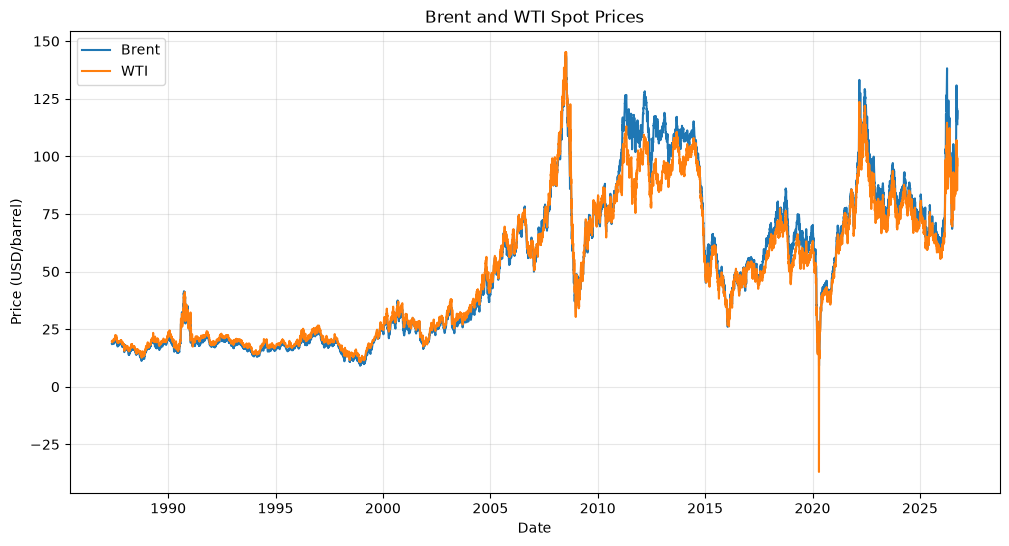

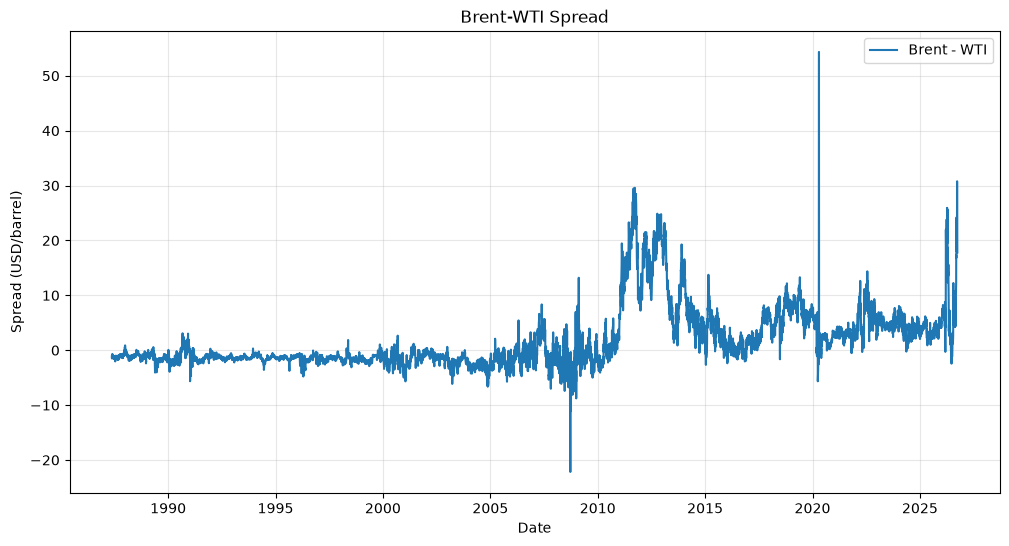

In [29]:
plot_spot_prices(prices)
plot_spread(prices)

# 4. JODI Oil Fundamentals

This section loads and cleans monthly oil market fundamentals from the JODI Oil database.

JODI data are reported by country, month, energy product, flow variable, unit of measurement, and observed value.

## 4.1 Country selection

We separate countries into two groups: countries related to the WTI market and countries related to the Brent market.

### WTI-related countries

The WTI benchmark is mainly linked to the North American oil market. We therefore keep:

- United States (`US`)
- Canada (`CA`)

### Brent-related countries

The Brent benchmark is more closely linked to the European and North Sea oil market. We therefore keep:

- United Kingdom (`GB`)
- Norway (`NO`)
- Netherlands (`NL`)
- Belgium (`BE`)

Other countries are excluded at this stage to keep the first version of the dataset simple. They may be added later in robustness checks.

## 4.2 JODI variables

The main JODI variables used in the project are:

- **Closing stock levels**: crude oil inventories at the end of the month.
- **Stock changes**: monthly changes in crude oil inventories.
- **Indigenous production**: domestic crude oil production.
- **Total imports**: crude oil imported by the country.
- **Total exports**: crude oil exported by the country.
- **Refinery intake**: crude oil used as input by refineries.

These variables describe the main components of the oil market balance: inventories, production, international trade, and refinery demand.

In [30]:
WTI_COUNTRIES = ["US", "CA"]

BRENT_COUNTRIES = ["GB", "NO", "NL", "BE"]

JODI_COUNTRIES = WTI_COUNTRIES + BRENT_COUNTRIES

In [31]:
jodi = clean_jodi_oil(
    input_dir=JODI_DIR,
    output_path=JODI_CLEAN_FILE,
    countries=JODI_COUNTRIES,
)

jodi.head()

variable,date,BE_CLOSTLV,BE_INDPROD,BE_REFINOBS,BE_STOCKCH,BE_TOTEXPSB,BE_TOTIMPSB,CA_CLOSTLV,CA_INDPROD,CA_REFINOBS,...,NO_REFINOBS,NO_STOCKCH,NO_TOTEXPSB,NO_TOTIMPSB,US_CLOSTLV,US_INDPROD,US_REFINOBS,US_STOCKCH,US_TOTEXPSB,US_TOTIMPSB
0,2002-01-01,4974.75,0.0,635.7219,523.27,0.0,650.6997,41338.33,1691.7006,1573.0284,...,279.3045,9647.33,2463.0019,17.3961,787774.0,5847.5806,14486.8710,5135.0,10.9355,8708.5484
1,2002-02-01,4775.76,0.0,604.8664,-198.99,0.0,598.0229,43070.28,1768.0750,1561.3250,...,280.0725,-1031.80,3002.6875,6.4200,802419.0,5871.3571,14306.1071,14645.0,4.4286,8753.3571
2,2002-03-01,4038.76,0.0,628.8274,-737.00,0.0,604.8155,45222.32,1789.4413,1521.5568,...,265.5326,-9603.11,2860.9384,0.0000,808272.0,5883.4516,14525.7419,5853.0,8.1935,8799.3871
3,2002-04-01,4267.23,0.0,678.5313,228.47,0.0,686.3927,47440.69,1822.0447,1398.7547,...,253.6613,4915.79,2960.7970,10.9853,809567.0,5858.7000,15325.1667,1295.0,7.6000,9300.8000
4,2002-05-01,4267.23,0.0,683.9835,0.00,0.0,683.7458,44735.90,1798.2426,1505.9523,...,267.4655,2785.86,2607.7281,19.5706,816316.0,5923.7097,15300.6452,6749.0,7.2258,9323.4194


# 5. Monthly Feature Engineering

The forecasting models are built at a monthly frequency.

The EIA Brent and WTI prices are originally daily, while JODI fundamentals are monthly. We therefore convert the daily spot prices into monthly observations and then merge them with monthly JODI fundamentals.

## 5.1 Monthly timing assumption

For each month, the price observation is defined at the first calendar day of the month. If that date is not available in the daily price data, we use the last available trading price before that date.

This gives a monthly price series that can be interpreted as information available at the beginning of the month.

To avoid look-ahead bias, JODI fundamentals are lagged by two months before being used as predictors. This means that JODI information dated at month `t` is only used from month `t+2` onward.

## 5.2 Build Monthly Price Features

We now convert the cleaned daily Brent and WTI prices into monthly observations.

From these monthly prices, we compute the Brent–WTI spread, Brent and WTI returns, spread changes, lagged variables, rolling means, rolling volatilities, and the next-month spread change target.

In [32]:
monthly_prices = build_monthly_price_features(
    prices=prices,
    output_path=MONTHLY_PRICE_FEATURES_FILE,
)

monthly_prices.head()

,date,Brent,WTI,spread,brent_return,wti_return,spread_change,spread_return,spread_lag_1,spread_change_lag_1,...,wti_return_rolling_mean_12,spread_return_rolling_mean_12,brent_return_rolling_vol_3,wti_return_rolling_vol_3,spread_return_rolling_vol_3,brent_return_rolling_vol_12,wti_return_rolling_vol_12,spread_return_rolling_vol_12,brent_wti_corr_12,target_spread_change_next_month
0,1987-06-01,18.65,19.55,-0.90,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.59
1,1987-07-01,18.98,20.47,-1.49,0.017694,0.047059,-0.59,-0.029364,-0.90,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.09
2,1987-08-01,20.03,21.43,-1.40,0.055321,0.046898,0.09,0.008423,-1.49,-0.59,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.22
3,1987-09-01,18.43,19.61,-1.18,-0.079880,-0.084928,0.22,0.005047,-1.40,0.09,...,NaN,NaN,0.241727,0.263812,0.072436,NaN,NaN,NaN,NaN,0.06
4,1987-10-01,18.50,19.62,-1.12,0.003798,0.000510,0.06,0.003288,-1.18,0.22,...,NaN,NaN,0.236373,0.231644,0.009040,NaN,NaN,NaN,NaN,-0.06


In [33]:
monthly_prices.columns.tolist()

['date',
 'Brent',
 'WTI',
 'spread',
 'brent_return',
 'wti_return',
 'spread_change',
 'spread_return',
 'spread_lag_1',
 'spread_change_lag_1',
 'brent_return_lag_1',
 'wti_return_lag_1',
 'spread_return_lag_1',
 'spread_lag_2',
 'spread_change_lag_2',
 'brent_return_lag_2',
 'wti_return_lag_2',
 'spread_return_lag_2',
 'spread_lag_3',
 'spread_change_lag_3',
 'brent_return_lag_3',
 'wti_return_lag_3',
 'spread_return_lag_3',
 'spread_change_rolling_mean_6',
 'brent_return_rolling_mean_6',
 'wti_return_rolling_mean_6',
 'spread_return_rolling_mean_6',
 'spread_change_rolling_mean_12',
 'brent_return_rolling_mean_12',
 'wti_return_rolling_mean_12',
 'spread_return_rolling_mean_12',
 'brent_return_rolling_vol_3',
 'wti_return_rolling_vol_3',
 'spread_return_rolling_vol_3',
 'brent_return_rolling_vol_12',
 'wti_return_rolling_vol_12',
 'spread_return_rolling_vol_12',
 'brent_wti_corr_12',
 'target_spread_change_next_month']

## 5.3 Merge with Lagged and Stationary JODI Fundamentals

We merge monthly price features with transformed JODI fundamentals with two adjustments:

1. Publication Lag ($M-2$): Fundamentals are lagged by two months (`jodi_lag = 2`) to match JODI's official reporting delay and prevent look-ahead bias.
2. Stationarity & Integration Balance: Raw physical levels (stocks, production, refining) are non-stationary $I(1)$ series. Regressing our stationary target ($I(0)$) on $I(1)$ levels creates an unbalanced regression and prevents decision trees from extrapolating. We therefore transform them into stationary $I(0)$ features (mainly YoY growth rates).

In [34]:
model_data = build_model_dataset(
    monthly_prices=monthly_prices,
    jodi=jodi,
    output_path=MODEL_DATASET_FILE,
    jodi_lag=2,
    stationarize=True
)

In [35]:
import pandas as pd
from statsmodels.tsa.stattools import adfuller

def adf_summary(series, name):
    s = series.dropna()
    res = adfuller(s, autolag="AIC", result_object=False)
    return {
        "Variable": name,
        "ADF Stat": round(res[0], 3),
        "p-value": round(res[1], 4),
        "Stationary (5%)": "Yes (I(0))" if res[1] < 0.05 else "No (I(1))"
    }

adf_table = pd.DataFrame([
    adf_summary(model_data["spread"], "Spread Level (Raw)"),
    adf_summary(model_data["target_spread_change_next_month"], "Target: Spread Change (dSpread)"),
    adf_summary(jodi["US_CLOSTLV"], "US Stocks (Raw JODI Level)"),
    adf_summary(model_data["US_CLOSTLV_yoy"], "US Stocks YoY (Transformed)"),
    adf_summary(jodi["US_INDPROD"], "US Production (Raw JODI Level)"),
    adf_summary(model_data["US_INDPROD_yoy"], "US Production YoY (Transformed)"),
])

display(adf_table)

,Variable,ADF Stat,p-value,Stationary (5%)
0,Spread Level (Raw),-2.455,0.1269,No (I(1))
1,Target: Spread Change (dSpread),-9.150,0.0000,Yes (I(0))
2,US Stocks (Raw JODI Level),-0.609,0.8689,No (I(1))
3,US Stocks YoY (Transformed),-3.230,0.0183,Yes (I(0))
4,US Production (Raw JODI Level),0.330,0.9787,No (I(1))
5,US Production YoY (Transformed),-3.000,0.0349,Yes (I(0))


### Discussion of Stationarity Diagnostics (ADF Tests)

We perform Augmented Dickey-Fuller tests to confirm the integration order of our variables:

1. Stationary Target ($I(0)$): The one-month-ahead spread change ($\Delta S_{t+1}$) is strictly stationary ($p\text{-value} < 0.0001$), while the raw spread level is non-stationary ($p = 0.1269$).
2. Non-Stationary Raw Fundamentals ($I(1)$): US inventories ($p = 0.8689$) and production ($p = 0.9787$) exhibit strong unit-root trends. Regressing a stationary target on non-stationary levels leads to econometric imbalance in linear models and prevents decision trees from extrapolating out-of-sample.
3. Validation of YoY Transforms ($I(0)$): Transforming levels into 12-month percentage changes removes structural trends and seasonal cycles. Both transformed US inventories ($p = 0.0183$) and production ($p = 0.0349$) are confirmed stationary at the 5% level.

Matching an $I(0)$ target with $I(0)$ predictors ensures valid inference and stable out-of-sample machine learning performance.

# 6. Modelling Sample

This section defines the final dataset used for the forecasting models.

We define the prediction target, the different feature sets, the modelling period, and we check for missing values before running the rolling-window forecasts.

The modelling sample starts in April 2003. Although JODI data begin in January 2002, computing 12-month YoY percentage changes requires 12 months of historical observations, and applying the 2-month publication lag ($M-2$) shifts the first features to April 2003.

## 6.1 Target Variable

The target variable is the one-month-ahead change in the Brent–WTI spread:

```text
target_{t+1} = spread_{t+1} - spread_t
```

A positive value means that the spread widened during the following month, while a negative value means that the spread narrowed.

In [36]:
TARGET_COL = "target_spread_change_next_month"

## 6.2 Price Feature Set

We first define the set of price-based predictors. These variables are computed only from past Brent and WTI prices.

They include spread levels, returns, lagged values, rolling means, rolling volatilities, and rolling correlations.

In [37]:
PRICE_FEATURES = [
    "spread_lag_1",                 # Mean-reversion anchor
    "spread_change_lag_1",          # Short-term spread momentum
    "spread_return_lag_1",          # Normalized relative return momentum
    "spread_change_rolling_mean_6", # Medium-term seasonal trend
    "spread_return_rolling_mean_12",# Annual trend
    "brent_return_lag_1",           # Brent-specific short shock
    "wti_return_lag_1",             # WTI-specific short shock
    "spread_return_rolling_vol_12", # Spread risk regime
    "brent_return_rolling_vol_12",  # Brent volatility
    "wti_return_rolling_vol_12",    # WTI volatility
    "brent_wti_corr_12",            # Market integration/decoupling
]

## 6.3 JODI Fundamental Feature Sets

We now define the JODI fundamental variables by geographical group.

The WTI-related fundamentals are based on North American countries, while the Brent-related fundamentals are based on European and North Sea countries.

In [38]:
# WTI Hub: United States (Cushing) and Canada (major pipeline flows)
WTI_PREFIXES = ["US_", "CA_"]

# Brent Hub: UK & Norway (North Sea fields), Netherlands & Belgium (ARA refining hub)
BRENT_PREFIXES = ["GB_", "NO_", "NL_", "BE_"]

WTI_FUNDAMENTAL_FEATURES = [
    col for col in model_data.columns
    if any(col.startswith(prefix) for prefix in WTI_PREFIXES)
]

BRENT_FUNDAMENTAL_FEATURES = [
    col for col in model_data.columns
    if any(col.startswith(prefix) for prefix in BRENT_PREFIXES)
]

ALL_FUNDAMENTAL_FEATURES = (
    WTI_FUNDAMENTAL_FEATURES
    + BRENT_FUNDAMENTAL_FEATURES
)

## 6.4 Feature Sets for Model Comparison

We compare four information sets:

1. price features only;
2. price features plus WTI-related fundamentals;
3. price features plus Brent-related fundamentals;
4. price features plus all fundamentals.

This allows us to test whether JODI fundamentals improve forecasting performance and whether the improvement comes mainly from one geographical group.

In [39]:
FEATURE_SETS = {
    "prices_only": PRICE_FEATURES,
    "prices_wti_fundamentals": PRICE_FEATURES + WTI_FUNDAMENTAL_FEATURES,
    "prices_brent_fundamentals": PRICE_FEATURES + BRENT_FUNDAMENTAL_FEATURES,
    "prices_all_fundamentals": PRICE_FEATURES + ALL_FUNDAMENTAL_FEATURES,
}

In [40]:
for name, features in FEATURE_SETS.items():
    print(f"{name}: {len(features)} features")

prices_only: 11 features
prices_wti_fundamentals: 23 features
prices_brent_fundamentals: 35 features
prices_all_fundamentals: 47 features


## 6.5 Modelling Period

The modelling sample starts in April 2003. 

Although JODI data begin in January 2002, computing 12-month YoY percentage changes requires 12 months of initialization, and applying the 2-month publication lag shifts the first fully observed fundamental features to April 2003. 

The end date is set to the last month for which all selected JODI variables are available. This avoids keeping incomplete months from 2026.

In [41]:
START_DATE = "2003-04-01"

JODI_FEATURES = [
    col for col in model_data.columns
    if col not in monthly_prices.columns
]

END_DATE = last_complete_date(
    data=model_data,
    columns=JODI_FEATURES,
)

print("Modelling Sample Range:", START_DATE, "to", END_DATE)

Modelling Sample Range: 2003-04-01 to 2026-06-01 00:00:00


## 6.6 Missing-Value Diagnostics

Before running the models, we check missing values in the price features, JODI features, and target variable over the selected modelling period.

In [42]:
check_missing_values(
    data=model_data,
    columns=PRICE_FEATURES,
    start_date=START_DATE,
    end_date=END_DATE,
)

Sample period: 2003-04-01 00:00:00 to 2026-06-01 00:00:00
Number of rows: 279
Number of checked columns: 11

Top 20 columns with missing values:


spread_lag_1                     0
spread_change_lag_1              0
spread_return_lag_1              0
spread_change_rolling_mean_6     0
spread_return_rolling_mean_12    0
brent_return_lag_1               0
wti_return_lag_1                 0
spread_return_rolling_vol_12     0
brent_return_rolling_vol_12      0
wti_return_rolling_vol_12        0
brent_wti_corr_12                0
dtype: int64

In [43]:
check_missing_values(
    data=model_data,
    columns=JODI_FEATURES,
    start_date=START_DATE,
    end_date=END_DATE,
)

Sample period: 2003-04-01 00:00:00 to 2026-06-01 00:00:00
Number of rows: 279
Number of checked columns: 36

Top 20 columns with missing values:


NO_TOTIMPSB_yoy    32
NL_TOTEXPSB_yoy     8
BE_TOTEXPSB_yoy     3
BE_CLOSTLV_yoy      0
BE_STOCKCH          0
BE_REFINOBS_yoy     0
BE_INDPROD_yoy      0
BE_TOTIMPSB_yoy     0
CA_REFINOBS_yoy     0
CA_STOCKCH          0
CA_CLOSTLV_yoy      0
CA_INDPROD_yoy      0
GB_CLOSTLV_yoy      0
GB_INDPROD_yoy      0
GB_REFINOBS_yoy     0
GB_STOCKCH          0
GB_TOTEXPSB_yoy     0
GB_TOTIMPSB_yoy     0
CA_TOTEXPSB_yoy     0
CA_TOTIMPSB_yoy     0
dtype: int64

In [44]:
check_missing_values(
    data=model_data,
    columns=[TARGET_COL],
    start_date=START_DATE,
    end_date=END_DATE,
)

Sample period: 2003-04-01 00:00:00 to 2026-06-01 00:00:00
Number of rows: 279
Number of checked columns: 1

Top 20 columns with missing values:


target_spread_change_next_month    0
dtype: int64

## 6.7 Final Modelling Sample

We now create the final modelling sample.

Rows outside the selected period are removed, and the last row is dropped if the next-month target is not available.

In [45]:
model_sample = model_data[
    (model_data["date"] >= START_DATE)
    & (model_data["date"] <= END_DATE)
].copy()

model_sample = model_sample.dropna(subset=[TARGET_COL])

model_sample = model_sample.reset_index(drop=True)

model_sample["date"].min(), model_sample["date"].max(), model_sample.shape

(Timestamp('2003-04-01 00:00:00'), Timestamp('2026-06-01 00:00:00'), (279, 75))

In [46]:
summarize_model_sample(
    model_sample=model_sample,
    feature_cols=PRICE_FEATURES + ALL_FUNDAMENTAL_FEATURES,
    target_col=TARGET_COL,
)

{'start_date': Timestamp('2003-04-01 00:00:00'),
 'end_date': Timestamp('2026-06-01 00:00:00'),
 'n_rows': 279,
 'n_features': 47,
 'missing_features': np.int64(43),
 'missing_target': np.int64(0)}

## 6.8 Feature Parsimony and Collinearity Diagnostics

With an empirical sample of approximately 280 monthly observations, using too many features poses a risk of overfitting and estimation variance. 

We first examine pairwise correlations among transformed JODI fundamentals.

In [47]:
# Compute pairwise correlation matrix across all fundamental features
corr_matrix = model_sample[ALL_FUNDAMENTAL_FEATURES].corr().abs()

high_corr_pairs = []
for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):
        col1 = corr_matrix.columns[i]
        col2 = corr_matrix.columns[j]
        val = corr_matrix.iloc[i, j]
        if val >= 0.85:
            high_corr_pairs.append({
                "Variable 1": col1,
                "Variable 2": col2,
                "Correlation": round(val, 3)
            })

high_corr_df = pd.DataFrame(high_corr_pairs).sort_values("Correlation", ascending=False)
print(f"Collinear pairs with |rho| >= 0.85: {len(high_corr_df)}")
display(high_corr_df)

Collinear pairs with |rho| >= 0.85: 1


,Variable 1,Variable 2,Correlation
0,BE_REFINOBS_yoy,BE_TOTIMPSB_yoy,0.983


We then remove collinear features with pairwise absolute correlation larger than $0.85$.

In [48]:
def filter_collinear_features(df, features, threshold=0.85):
    """
    Remove collinear features with pairwise absolute correlation >= threshold.
    """
    corr_mat = df[features].corr().abs()
    to_drop = set()

    for i in range(len(features)):
        col_i = features[i]
        if col_i in to_drop:
            continue
        for j in range(i + 1, len(features)):
            col_j = features[j]
            if col_j in to_drop:
                continue
            if corr_mat.loc[col_i, col_j] >= threshold:
                to_drop.add(col_j)

    retained = [f for f in features if f not in to_drop]
    print(f"Filter (|rho| >= {threshold}): {len(features)} -> {len(retained)} retained ({len(to_drop)} dropped).")
    return retained


# Filter collinearity within WTI and Brent fundamental groups
WTI_FEATURES_CLEAN = filter_collinear_features(model_sample, WTI_FUNDAMENTAL_FEATURES, threshold=0.85)
BRENT_FEATURES_CLEAN = filter_collinear_features(model_sample, BRENT_FUNDAMENTAL_FEATURES, threshold=0.85)

# Construct final information sets
FEATURE_SETS = {
    "prices_only": PRICE_FEATURES,
    "prices_wti_fundamentals": PRICE_FEATURES + WTI_FEATURES_CLEAN,
    "prices_brent_fundamentals": PRICE_FEATURES + BRENT_FEATURES_CLEAN,
    "prices_all_fundamentals": PRICE_FEATURES + filter_collinear_features(
        model_sample, WTI_FEATURES_CLEAN + BRENT_FEATURES_CLEAN, threshold=0.85
    ),
}

print("\n--- FINAL PARSIMONIOUS FEATURE SETS ---")
for name, f_list in FEATURE_SETS.items():
    print(f"{name:30s}: {len(f_list)} features")

Filter (|rho| >= 0.85): 12 -> 12 retained (0 dropped).
Filter (|rho| >= 0.85): 24 -> 23 retained (1 dropped).
Filter (|rho| >= 0.85): 35 -> 35 retained (0 dropped).

--- FINAL PARSIMONIOUS FEATURE SETS ---
prices_only                   : 11 features
prices_wti_fundamentals       : 23 features
prices_brent_fundamentals     : 34 features
prices_all_fundamentals       : 46 features


# 7. Forecasting Models

This section estimates forecasting models for the monthly change in the Brent–WTI spread.

The models are evaluated using a rolling-window procedure. At each date, the model is trained on a fixed number of past monthly observations and then used to predict the next observation. The training window then moves forward by one month.

This ensures that predictions are generated out-of-sample and that the chronological order of the data is respected.

We start with a Ridge regression as a regularized linear benchmark. Non-linear models such as Random Forest and LightGBM can then be added as extensions.

## 7.1 Rolling-Window Setup

We use a rolling training window of 120 months, corresponding to 10 years of monthly data.

In [49]:
TRAIN_WINDOW = 120
TEST_SIZE = 1

FIRST_OOS_DATE = model_sample["date"].iloc[TRAIN_WINDOW]

TRAIN_START = model_sample["date"].iloc[0]
TRAIN_END = model_sample["date"].iloc[TRAIN_WINDOW - 1]

print("Train Start:", TRAIN_START)
print("Train End  :", TRAIN_END)
print("First OOS  :", FIRST_OOS_DATE)

Train Start: 2003-04-01 00:00:00
Train End  : 2013-03-01 00:00:00
First OOS  : 2013-04-01 00:00:00


In [50]:
TRAIN_WINDOWS = [60, 84, 120, 180]

models = get_models()

diagnostics_df, diagnostics_predictions = run_overfitting_diagnostics(
    data=model_sample,
    feature_sets=FEATURE_SETS,
    target_col=TARGET_COL,
    models=models,
    train_windows=TRAIN_WINDOWS,
    test_size=1,
)

# Save the full diagnostics
diagnostics_df.to_csv(PROCESSED_DIR / "overfitting_diagnostics.csv", index=False)

Running naive_zero | prices_only | train_window=60
Running historical_mean | prices_only | train_window=60
Running ar1 | prices_only | train_window=60
Running ridge | prices_only | train_window=60
Running random_forest | prices_only | train_window=60
Running lightgbm | prices_only | train_window=60
Running naive_zero | prices_wti_fundamentals | train_window=60
Running historical_mean | prices_wti_fundamentals | train_window=60
Running ar1 | prices_wti_fundamentals | train_window=60
Running ridge | prices_wti_fundamentals | train_window=60
Running random_forest | prices_wti_fundamentals | train_window=60
Running lightgbm | prices_wti_fundamentals | train_window=60
Running naive_zero | prices_brent_fundamentals | train_window=60
Running historical_mean | prices_brent_fundamentals | train_window=60
Running ar1 | prices_brent_fundamentals | train_window=60
Running ridge | prices_brent_fundamentals | train_window=60
Running random_forest | prices_brent_fundamentals | train_window=60
Running

In [51]:
COMMON_OOS_START = max(
    preds["oos"]["date"].min()
    for preds in diagnostics_predictions.values()
)

print("Common OOS Evaluation Start Date:", COMMON_OOS_START)

Common OOS Evaluation Start Date: 2018-04-01 00:00:00


We evaluate all models against three standard econometric benchmarks:
1. Naive model: $\hat{\Delta S}_{t+1} = 0$. Represents the market efficiency baseline.
2. Historical Mean: $\hat{\Delta S}_{t+1} = \bar{\mu}_{1:t}$. 
3. Univariate AR(1): $\Delta S_{t+1} = \alpha + \beta \Delta S_t$. 

To formally assess whether an ML model delivers statistically significant improvements over the naive benchmark, we compute the Diebold-Mariano test statistic:
$$DM = \frac{\bar{d}}{\sqrt{\hat{V}(\bar{d})}} \xrightarrow{d} \mathcal{N}(0, 1)$$
where $d_t = e_{\text{model}, t}^2 - e_{\text{naive}, t}^2$. A negative $DM$ statistic with a $p\text{-value} < 0.05$ indicates statistically significant predictive outperformance.

In [52]:
import pandas as pd
import numpy as np
from scripts.models import diebold_mariano_test

# 1. Define common out-of-sample start date
COMMON_OOS_START = max(
    preds["oos"]["date"].min()
    for preds in diagnostics_predictions.values()
)

print(f"Common OOS Evaluation Period starts on: {COMMON_OOS_START.date()}")

# 2. Extract the baseline Naive Zero predictions on the common evaluation window
# (Naive zero is identical across feature sets, so we take the prices_only one)
ref_naive_key = f"prices_only__naive_zero__window_{TRAIN_WINDOWS[-1]}"
ref_naive_preds = diagnostics_predictions[ref_naive_key]["oos"]
ref_naive_preds = ref_naive_preds[ref_naive_preds["date"] >= COMMON_OOS_START]

common_results = []

for key, preds_dict in diagnostics_predictions.items():
    oos_preds = preds_dict["oos"].copy()
    oos_preds = oos_preds[oos_preds["date"] >= COMMON_OOS_START]

    metrics = forecast_metrics(oos_preds)

    parts = key.split("__")
    feature_set = parts[0]
    model_name = parts[1]
    train_window = int(parts[2].replace("window_", ""))

    # Compute Diebold-Mariano test against Naive Zero
    dm_stat, dm_pval = diebold_mariano_test(
        y_true=oos_preds["y_true"].values,
        y_pred1=oos_preds["y_pred"].values,
        y_pred2=ref_naive_preds["y_pred"].values,
        h=1,
        loss_type="sq",
    )

    common_results.append(
        {
            "train_window": train_window,
            "feature_set": feature_set,
            "model": model_name,
            "n_oos": len(oos_preds),
            "rmse": metrics["rmse"],
            "mae": metrics["mae"],
            "r2": metrics["r2"],
            "directional_acc": metrics["directional_accuracy"],
            "dm_stat": round(dm_stat, 3),
            "dm_pvalue": round(dm_pval, 4),
            "sig_better_than_naive": "Yes (p < 0.05)" if (dm_pval < 0.05 and dm_stat < 0) else "No",
        }
    )

common_metrics = pd.DataFrame(common_results)

Common OOS Evaluation Period starts on: 2018-04-01


In [54]:
# Filter and display the top 15 configurations sorted by RMSE
print("--- TOP FORECASTING MODELS VS BENCHMARKS (Sorted by RMSE) ---")
display(
    common_metrics.sort_values("rmse").head(15)[
        [
            "train_window",
            "feature_set",
            "model",
            "rmse",
            "mae",
            "r2",
            "directional_acc",
            "dm_stat",
            "dm_pvalue",
            "sig_better_than_naive",
        ]
    ]
)

# Display specifically the Econometric Benchmarks for direct comparison
print("\n--- ECONOMETRIC BENCHMARKS PERFORMANCE (Baseline Reference) ---")
benchmarks_summary = common_metrics[
    common_metrics["model"].isin(["naive_zero", "historical_mean", "ar1"])
    & (common_metrics["feature_set"] == "prices_only")
]
display(benchmarks_summary[["train_window", "model", "rmse", "mae", "r2", "directional_acc"]])

--- TOP FORECASTING MODELS VS BENCHMARKS (Sorted by RMSE) ---


,train_window,feature_set,model,rmse,mae,r2,directional_acc,dm_stat,dm_pvalue,sig_better_than_naive
77,180,prices_only,lightgbm,2.953080,2.050348,0.083286,0.575758,-1.182,0.2403,No
83,180,prices_wti_fundamentals,lightgbm,2.976796,2.092444,0.068502,0.484848,-0.879,0.3814,No
76,180,prices_only,random_forest,2.985338,2.049216,0.063149,0.555556,-1.246,0.2158,No
53,120,prices_only,lightgbm,2.995993,2.065972,0.056449,0.575758,-0.834,0.4064,No
95,180,prices_all_fundamentals,lightgbm,3.007460,2.131036,0.049213,0.555556,-0.725,0.4701,No
27,84,prices_only,ridge,3.010743,2.086562,0.047136,0.595960,-0.978,0.3303,No
28,84,prices_only,random_forest,3.016753,2.098116,0.043328,0.565657,-1.308,0.1938,No
82,180,prices_wti_fundamentals,random_forest,3.019218,2.082041,0.041764,0.535354,-1.134,0.2596,No
89,180,prices_brent_fundamentals,lightgbm,3.020003,2.162024,0.041265,0.545455,-0.650,0.5171,No
94,180,prices_all_fundamentals,random_forest,3.036066,2.073952,0.031040,0.565657,-1.353,0.1790,No



--- ECONOMETRIC BENCHMARKS PERFORMANCE (Baseline Reference) ---


,train_window,model,rmse,mae,r2,directional_acc
0,60,naive_zero,3.084669,2.118283,-0.000232,0.000000
1,60,historical_mean,3.107882,2.137114,-0.015342,0.434343
2,60,ar1,3.131647,2.106213,-0.030930,0.535354
24,84,naive_zero,3.084669,2.118283,-0.000232,0.000000
25,84,historical_mean,3.095719,2.135791,-0.007411,0.454545
26,84,ar1,3.049236,2.052793,0.022615,0.555556
48,120,naive_zero,3.084669,2.118283,-0.000232,0.000000
49,120,historical_mean,3.097244,2.123404,-0.008404,0.454545
50,120,ar1,3.049792,2.069065,0.022258,0.555556
72,180,naive_zero,3.084669,2.118283,-0.000232,0.000000


In [55]:
common_metrics.sort_values("rmse").head(20)

,train_window,feature_set,model,n_oos,rmse,mae,r2,directional_acc,dm_stat,dm_pvalue,sig_better_than_naive
77,180,prices_only,lightgbm,99,2.953080,2.050348,0.083286,0.575758,-1.182,0.2403,No
83,180,prices_wti_fundamentals,lightgbm,99,2.976796,2.092444,0.068502,0.484848,-0.879,0.3814,No
76,180,prices_only,random_forest,99,2.985338,2.049216,0.063149,0.555556,-1.246,0.2158,No
53,120,prices_only,lightgbm,99,2.995993,2.065972,0.056449,0.575758,-0.834,0.4064,No
95,180,prices_all_fundamentals,lightgbm,99,3.007460,2.131036,0.049213,0.555556,-0.725,0.4701,No
27,84,prices_only,ridge,99,3.010743,2.086562,0.047136,0.595960,-0.978,0.3303,No
28,84,prices_only,random_forest,99,3.016753,2.098116,0.043328,0.565657,-1.308,0.1938,No
82,180,prices_wti_fundamentals,random_forest,99,3.019218,2.082041,0.041764,0.535354,-1.134,0.2596,No
89,180,prices_brent_fundamentals,lightgbm,99,3.020003,2.162024,0.041265,0.545455,-0.650,0.5171,No
94,180,prices_all_fundamentals,random_forest,99,3.036066,2.073952,0.031040,0.565657,-1.353,0.1790,No


In [56]:
common_metrics.sort_values("directional_acc", ascending=False).head(20)

,train_window,feature_set,model,n_oos,rmse,mae,r2,directional_acc,dm_stat,dm_pvalue,sig_better_than_naive
87,180,prices_brent_fundamentals,ridge,99,3.100381,2.118019,-0.010447,0.616162,0.143,0.8869,No
81,180,prices_wti_fundamentals,ridge,99,3.085100,2.177147,-0.000511,0.616162,0.003,0.9973,No
27,84,prices_only,ridge,99,3.010743,2.086562,0.047136,0.595960,-0.978,0.3303,No
41,84,prices_brent_fundamentals,lightgbm,99,3.125343,2.267491,-0.026783,0.595960,0.354,0.7242,No
47,84,prices_all_fundamentals,lightgbm,99,3.240479,2.396287,-0.103829,0.575758,1.304,0.1951,No
53,120,prices_only,lightgbm,99,2.995993,2.065972,0.056449,0.575758,-0.834,0.4064,No
77,180,prices_only,lightgbm,99,2.953080,2.050348,0.083286,0.575758,-1.182,0.2403,No
63,120,prices_brent_fundamentals,ridge,99,3.097938,2.156094,-0.008855,0.575758,0.146,0.8842,No
51,120,prices_only,ridge,99,3.074909,2.118333,0.006088,0.575758,-0.104,0.9175,No
28,84,prices_only,random_forest,99,3.016753,2.098116,0.043328,0.565657,-1.308,0.1938,No
